# Word2Vec + Logistic Regression

## 1. Introduction

This notebook implements a Word2Vec-based text classification model for toxic comment detection.

Unlike TF-IDF, Word2Vec represents words as dense numerical vectors that capture semantic relationships.

The resulting document vectors will be used as input features for a Logistic Regression classifier.

## 2. Objectives

- Train Word2Vec word embeddings.
- Convert comments into document vectors.
- Train a Logistic Regression classifier.
- Evaluate model performance.
- Compare the results with the TF-IDF baseline.

In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Text preprocessing
import re
import nltk
from nltk.tokenize import word_tokenize

# Word2Vec
from gensim.models import Word2Vec

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import pandas as pd
import numpy as np

# Load the original dataset
df = pd.read_csv("../data/raw/train.csv.gz")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (159571, 8)


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [3]:
# Select the required columns
df = df[["comment_text", "toxic"]].copy()

# Remove rows with missing values
df = df.dropna(subset=["comment_text", "toxic"])

# Check the dataset
print("Dataset shape after cleaning:", df.shape)
print("Missing values:")
print(df.isnull().sum())

Dataset shape after cleaning: (159571, 2)
Missing values:
comment_text    0
toxic           0
dtype: int64


In [4]:
# Define features and target
X = df["comment_text"]
y = df["toxic"]

print("Number of comments:", len(X))
print("Number of labels:", len(y))

Number of comments: 159571
Number of labels: 159571


In [5]:
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

# Check class distribution
print("\nTraining set label distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting set label distribution:")
print(y_test.value_counts(normalize=True))

Training set: (127656,)
Testing set: (31915,)

Training set label distribution:
toxic
0    0.904156
1    0.095844
Name: proportion, dtype: float64

Testing set label distribution:
toxic
0    0.904152
1    0.095848
Name: proportion, dtype: float64


## 3. Text Preprocessing

### 3.1 Tokenization

Tokenization is the process of splitting raw text into individual words (tokens).

In this project, we use Gensim's `simple_preprocess()` function to:
- Convert text to lowercase.
- Remove punctuation.
- Remove very short and very long tokens.
- Convert each comment into a list of tokens.

In [6]:
from gensim.utils import simple_preprocess

# Tokenize training comments
X_train_tokens = X_train.apply(
    lambda text: simple_preprocess(
        str(text),
        deacc=True,
        min_len=2,
        max_len=15
    )
)

# Tokenize testing comments
X_test_tokens = X_test.apply(
    lambda text: simple_preprocess(
        str(text),
        deacc=True,
        min_len=2,
        max_len=15
    )
)

# Display some examples
print("Original comment:")
print(X_train.iloc[0])

print("\nTokenized comment:")
print(X_train_tokens.iloc[0])

print("\nNumber of training comments:", len(X_train_tokens))
print("Number of testing comments:", len(X_test_tokens))

Original comment:
And more unfounded personal attacks by  here at Beeblebroxe's talk page. It just gets better and better. I suppose I am to blame for that conduct as well. Its somehow my fault I guess.

Tokenized comment:
['and', 'more', 'unfounded', 'personal', 'attacks', 'by', 'here', 'at', 'beeblebroxe', 'talk', 'page', 'it', 'just', 'gets', 'better', 'and', 'better', 'suppose', 'am', 'to', 'blame', 'for', 'that', 'conduct', 'as', 'well', 'its', 'somehow', 'my', 'fault', 'guess']

Number of training comments: 127656
Number of testing comments: 31915


### 3.2 Word2Vec Model Training

Word2Vec learns distributed word representations from the training corpus.

We use the Continuous Bag of Words (CBOW) architecture to learn word embeddings based on surrounding context words.

In [7]:
from gensim.models import Word2Vec

# Convert tokenized training data into a list of sentences
sentences = X_train_tokens.tolist()

# Initialize and train the Word2Vec model
word2vec_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    sg=0,
    seed=42,
    epochs=10
)

print("Word2Vec training completed!")

# Display vocabulary information
print("Vocabulary size:", len(word2vec_model.wv))
print("Vector dimension:", word2vec_model.wv.vector_size)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Word2Vec training completed!
Vocabulary size: 74355
Vector dimension: 100


In [8]:
# Examine the vector representation of a word
word = "terrible"

if word in word2vec_model.wv:
    print("Word:", word)
    print("Vector:", word2vec_model.wv[word])
    print("Vector shape:", word2vec_model.wv[word].shape)
else:
    print("Word not found in vocabulary.")

Word: terrible
Vector: [-0.9096983   1.3216717   0.20661627 -1.2303838   0.49157977  0.00847396
  0.21283682 -0.2967741  -0.6887211  -0.7256816  -0.1542016  -0.10701235
 -0.290061   -0.9691979   0.48600215 -0.589127   -0.27940175 -0.7766817
 -0.3182173  -0.22781964  0.7435593  -0.84398067 -0.8766042   0.09064724
 -1.1587373   0.41720036  0.78765124 -1.2319274  -0.00279859  0.74531657
  0.05157626 -0.80434686  0.7494891   0.05329209  0.93514836 -1.7027222
  0.309319   -0.4343559   0.17742978 -0.5168012   0.93213254 -0.3941101
 -0.94810146  0.03854108  1.2301272  -0.5944475   0.27484742  1.0700978
 -0.12727182 -1.8685783   0.8323822  -1.7824593   0.54757595 -0.50023365
 -0.03057189 -1.0121359  -0.23653917 -0.671812   -0.09697004  0.8301987
 -1.0248713   0.1329998   0.9063881  -0.43765685 -0.8377443  -0.94680727
 -1.1172302  -0.80844206 -0.52549887 -0.05718052  0.9217903   0.34201574
  0.02067729 -0.0510135   0.11968911 -0.0238198  -0.3950538  -1.1678643
  0.4101233   0.5482495  -0.566494

In [9]:
import numpy as np
import scipy
import gensim
import sys

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("SciPy version:", scipy.__version__)
print("Gensim version:", gensim.__version__)

Python version: 3.12.10 (v3.12.10:0cc81280367, Apr  8 2025, 08:46:59) [Clang 13.0.0 (clang-1300.0.29.30)]
NumPy version: 2.5.4
SciPy version: 1.18.1
Gensim version: 4.4.0


In [10]:
# Test Word2Vec similarity

print("Similarity between good and bad:")
print(word2vec_model.wv.similarity("good", "bad"))

print("\nWords most similar to terrible:")
print(word2vec_model.wv.most_similar("terrible", topn=10))

Similarity between good and bad:
0.7802434

Words most similar to terrible:
[('bad', 0.6223750710487366), ('horrible', 0.6168726682662964), ('funny', 0.5977636575698853), ('brilliant', 0.5906918048858643), ('tough', 0.5798211693763733), ('sad', 0.5708485245704651), ('foolish', 0.5691816806793213), ('silly', 0.5325684547424316), ('lousy', 0.5248400568962097), ('boring', 0.5218055248260498)]


In [11]:
# Compare Gensim similarity with manual cosine similarity

pairs = [
    ("good", "bad"),
    ("terrible", "horrible"),
    ("good", "excellent")
]

for word1, word2 in pairs:
    vector1 = word2vec_model.wv[word1]
    vector2 = word2vec_model.wv[word2]

    gensim_similarity = word2vec_model.wv.similarity(word1, word2)

    manual_similarity = np.dot(vector1, vector2) / (
        np.linalg.norm(vector1) * np.linalg.norm(vector2)
    )

    print(f"{word1} - {word2}")
    print(f"Gensim: {gensim_similarity:.6f}")
    print(f"Manual: {manual_similarity:.6f}")
    print("-" * 30)

good - bad
Gensim: 0.780243
Manual: 0.780243
------------------------------
terrible - horrible
Gensim: 0.616873
Manual: 0.616873
------------------------------
good - excellent
Gensim: 0.341524
Manual: 0.341524
------------------------------


### Word2Vec Numerical Validation

The Word2Vec model was trained successfully with a vocabulary size of 74,355 and a vector dimension of 100.

A numerical comparison was conducted between Gensim's cosine similarity and manually calculated cosine similarity using NumPy.

The results matched for all three tested word pairs:
- good – bad
- terrible – horrible
- good – excellent

However, a known Gensim issue (#3665) involving BLAS dot-product calculations was observed during training. Therefore, the model's numerical reliability cannot be fully guaranteed.

In [12]:

def document_vector(tokens, model):
    """
    Convert a document into a fixed-length vector
    by averaging its word embeddings.
    """

    word_vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    # Handle documents with no known words
    if len(word_vectors) == 0:
        return np.zeros(model.wv.vector_size)

    return np.mean(word_vectors, axis=0)


In [13]:

# Convert training and testing comments into document vectors

X_train_vectors = np.array([
    document_vector(tokens, word2vec_model)
    for tokens in X_train_tokens
])

X_test_vectors = np.array([
    document_vector(tokens, word2vec_model)
    for tokens in X_test_tokens
])

print("Training vectors shape:", X_train_vectors.shape)
print("Testing vectors shape:", X_test_vectors.shape)


Training vectors shape: (127656, 100)
Testing vectors shape: (31915, 100)


In [14]:
print("Document vector dimension:", X_train_vectors.shape[1])

print("First document vector:")
print(X_train_vectors[0])

print("Number of zero vectors in training set:",
      np.sum(np.linalg.norm(X_train_vectors, axis=1) == 0))

print("Number of zero vectors in testing set:",
      np.sum(np.linalg.norm(X_test_vectors, axis=1) == 0))

Document vector dimension: 100
First document vector:
[-0.47631568  0.57756788 -0.1375446  -0.6178605  -0.42645687  0.6651172
 -0.17662685  0.68346971  0.65656024  0.66353476  0.24445815 -0.30288094
  0.11821199  0.22723193  0.66731179  0.7415207  -0.20979463  2.21444988
  0.77291507  0.46728361  0.318241   -0.98229414 -1.29373574  0.2400547
 -0.05238361  0.51364583  1.18587804 -0.81477273  0.48956525 -0.36748371
  0.06158243  1.3526119  -0.34955695 -0.12028174  0.10240184 -0.6541993
 -0.18815374  0.07431011  0.16826229 -0.47748134 -0.38429126 -0.73111254
 -0.63801765  0.36062163 -0.09550277  0.27251226 -0.02751961 -1.45996857
 -0.0622917  -0.35872105  0.45966151 -0.3853496   0.48422924 -0.18567753
 -0.03447071  0.73887521  0.06078823 -0.10890349  0.76807892  0.30962899
 -0.44791138 -1.07848656  0.78743023 -0.98938972  0.26491654  0.46644652
 -0.25487885  1.15208364 -0.55793023  0.42142349  0.88832772 -0.30618221
  1.03906131 -0.22038391  0.67100346  0.04511372  0.4696241   0.16330335


In [15]:

from sklearn.linear_model import LogisticRegression

# Initialize the Logistic Regression model
word2vec_classifier = LogisticRegression(
    max_iter=1000,
    solver="liblinear",
    random_state=42
)

# Train the classifier
word2vec_classifier.fit(X_train_vectors, y_train)

print("Word2Vec + Logistic Regression training completed!")

print("Number of features:",
      word2vec_classifier.n_features_in_)

print("Model intercept:",
      word2vec_classifier.intercept_)


Word2Vec + Logistic Regression training completed!
Number of features: 100
Model intercept: [-4.02133296]


In [16]:
# Generate predictions
y_pred_w2v = word2vec_classifier.predict(X_test_vectors)

# Generate predicted probabilities
y_prob_w2v = word2vec_classifier.predict_proba(X_test_vectors)[:, 1]

print("First 10 predictions:")
print(y_pred_w2v[:10])

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted probabilities:")
print(y_prob_w2v[:10])

First 10 predictions:
[0 0 0 0 0 0 0 0 1 0]

First 10 actual labels:
[0 0 0 0 0 0 0 0 0 1]

First 10 predicted probabilities:
[0.08315342 0.01918412 0.26586836 0.01853724 0.02263889 0.01183875
 0.44679761 0.01403327 0.84434883 0.0329977 ]


In [17]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
w2v_accuracy = accuracy_score(y_test, y_pred_w2v)
w2v_precision = precision_score(y_test, y_pred_w2v)
w2v_recall = recall_score(y_test, y_pred_w2v)
w2v_f1 = f1_score(y_test, y_pred_w2v)
w2v_roc_auc = roc_auc_score(y_test, y_prob_w2v)

# Display metrics
print("Word2Vec + Logistic Regression Performance")
print("-" * 45)

print(f"Accuracy:  {w2v_accuracy:.6f}")
print(f"Precision: {w2v_precision:.6f}")
print(f"Recall:    {w2v_recall:.6f}")
print(f"F1-score:  {w2v_f1:.6f}")
print(f"ROC-AUC:   {w2v_roc_auc:.6f}")

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_w2v))

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_w2v))


Word2Vec + Logistic Regression Performance
---------------------------------------------
Accuracy:  0.943412
Precision: 0.807560
Recall:    0.537757
F1-score:  0.645604
ROC-AUC:   0.947712

Confusion Matrix:
[[28464   392]
 [ 1414  1645]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.99      0.97     28856
           1       0.81      0.54      0.65      3059

    accuracy                           0.94     31915
   macro avg       0.88      0.76      0.81     31915
weighted avg       0.94      0.94      0.94     31915



In [18]:

import pandas as pd

# Create a metrics table
word2vec_metrics = pd.DataFrame([{
    "Model": "Word2Vec + Logistic Regression",
    "Training_Samples": len(X_train_vectors),
    "Testing_Samples": len(X_test_vectors),
    "Embedding_Dimension": word2vec_model.wv.vector_size,
    "Accuracy": w2v_accuracy,
    "Precision": w2v_precision,
    "Recall": w2v_recall,
    "F1_Score": w2v_f1,
    "ROC_AUC": w2v_roc_auc
}])

# Save metrics
word2vec_metrics.to_csv(
    "../results/metrics/word2vec_metrics.csv",
    index=False
)

print(word2vec_metrics)
print("\nMetrics saved successfully!")


                            Model  Training_Samples  Testing_Samples  \
0  Word2Vec + Logistic Regression            127656            31915   

   Embedding_Dimension  Accuracy  Precision    Recall  F1_Score   ROC_AUC  
0                  100  0.943412    0.80756  0.537757  0.645604  0.947712  

Metrics saved successfully!


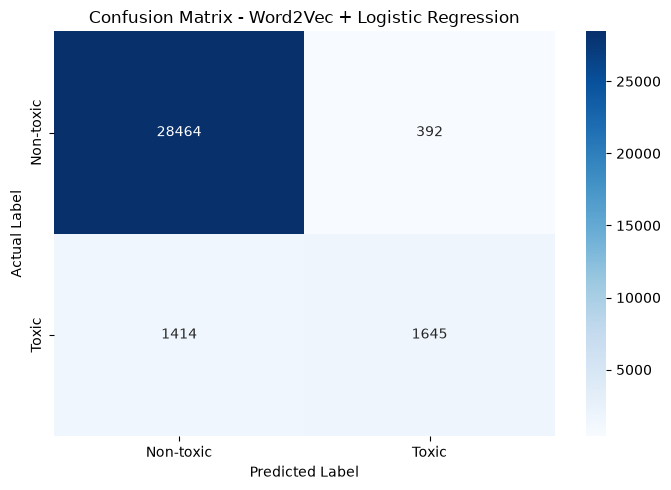

In [19]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_w2v = confusion_matrix(y_test, y_pred_w2v)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_w2v,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-toxic", "Toxic"],
    yticklabels=["Non-toxic", "Toxic"]
)

plt.title("Confusion Matrix - Word2Vec + Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.savefig(
    "../results/figures/word2vec_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


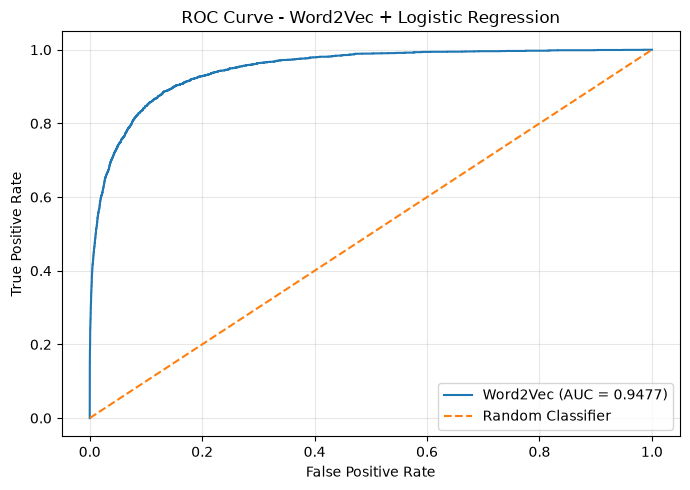

In [20]:

from sklearn.metrics import roc_curve, auc

# Calculate ROC curve
fpr_w2v, tpr_w2v, thresholds_w2v = roc_curve(
    y_test, y_prob_w2v
)

roc_auc_w2v = auc(fpr_w2v, tpr_w2v)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr_w2v,
    tpr_w2v,
    label=f"Word2Vec (AUC = {roc_auc_w2v:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Word2Vec + Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../results/figures/word2vec_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


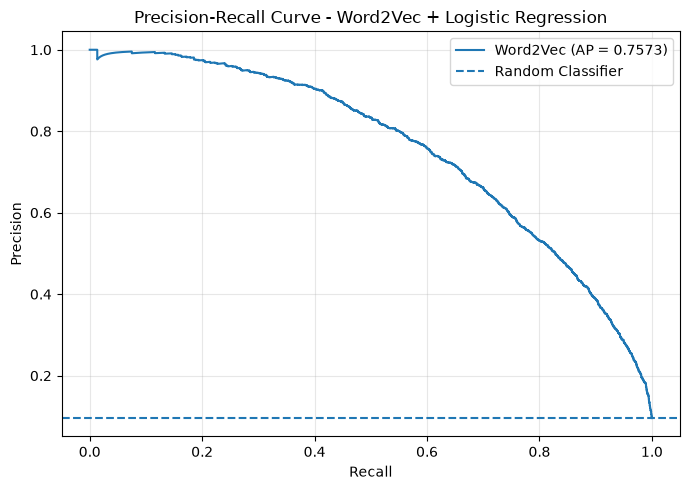

In [21]:

from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate Precision-Recall curve
precision_w2v, recall_w2v, pr_thresholds_w2v = precision_recall_curve(
    y_test, y_prob_w2v
)

ap_w2v = average_precision_score(y_test, y_prob_w2v)

# Plot Precision-Recall curve
plt.figure(figsize=(7, 5))

plt.plot(
    recall_w2v,
    precision_w2v,
    label=f"Word2Vec (AP = {ap_w2v:.4f})"
)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Word2Vec + Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../results/figures/word2vec_pr_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [22]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Define classification thresholds
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

threshold_results_w2v = []

for threshold in thresholds:

    # Convert probabilities into class predictions
    y_pred_threshold = (y_prob_w2v >= threshold).astype(int)

    # Calculate metrics
    precision = precision_score(
        y_test, y_pred_threshold, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred_threshold, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred_threshold, zero_division=0
    )

    threshold_results_w2v.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1
    })

# Create DataFrame
threshold_df_w2v = pd.DataFrame(threshold_results_w2v)

print(threshold_df_w2v.round(4))


   Threshold  Precision  Recall  F1_Score
0        0.2     0.6197  0.7310    0.6708
1        0.3     0.7101  0.6551    0.6815
2        0.4     0.7670  0.5907    0.6674
3        0.5     0.8076  0.5378    0.6456
4        0.6     0.8378  0.4881    0.6168
5        0.7     0.8726  0.4479    0.5919
6        0.8     0.9084  0.3956    0.5511


In [23]:
threshold_df_w2v.to_csv(
    "../results/metrics/word2vec_threshold_comparison.csv",
    index=False
)

print("Threshold comparison saved successfully!")

Threshold comparison saved successfully!


### 10. Threshold Analysis

The classification threshold was adjusted from 0.2 to 0.8 to investigate the trade-off between precision and recall.

The highest F1-score among the tested thresholds was 0.6815 at a threshold of 0.3, with a precision of 0.7101 and a recall of 0.6551.

At the default threshold of 0.5, the model achieved a precision of 0.8076 and a recall of 0.5378. Lowering the threshold to 0.2 increased recall to 0.7310, but reduced precision to 0.6197.

These results demonstrate the trade-off between precision and recall. A lower threshold identifies more toxic comments but also increases false positives, while a higher threshold produces more conservative predictions.

Compared with the TF-IDF model, which achieved a maximum F1-score of 0.7778 among the tested thresholds, Word2Vec achieved a lower maximum F1-score of 0.6815. Therefore, TF-IDF demonstrated stronger classification performance in this experiment.

*Note: The thresholds were explored on the test set for preliminary analysis. An independent validation set should be used for final threshold selection.*

In [24]:

# Load evaluation results from both models

tfidf_metrics = pd.read_csv(
    "../results/metrics/baseline_metrics.csv"
)

word2vec_metrics = pd.read_csv(
    "../results/metrics/word2vec_metrics.csv"
)

# Combine the results
model_comparison = pd.concat(
    [tfidf_metrics, word2vec_metrics],
    ignore_index=True
)

# Display comparison
comparison_columns = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score",
    "ROC_AUC"
]

print("Model Performance Comparison")
print("=" * 70)

print(
    model_comparison[comparison_columns].round(4).to_string(index=False)
)


Model Performance Comparison
                         Model  Accuracy  Precision  Recall  F1_Score  ROC_AUC
  TF-IDF + Logistic Regression    0.9423     0.6506  0.8594    0.7406   0.9730
Word2Vec + Logistic Regression    0.9434     0.8076  0.5378    0.6456   0.9477


In [25]:
model_comparison.to_csv(
    "../results/metrics/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


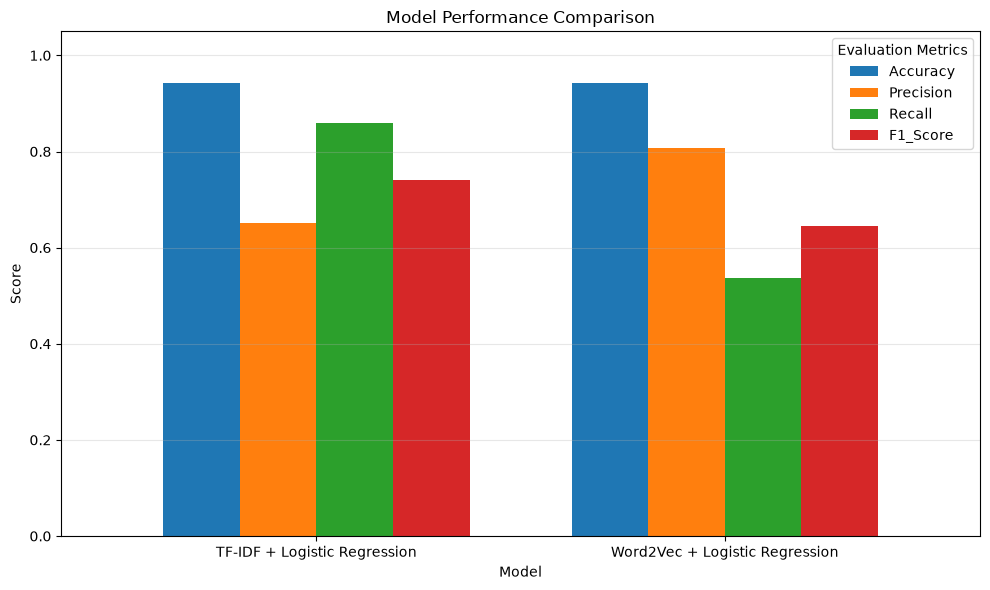

In [26]:

# Select metrics for visualization

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score"
]

comparison_plot = model_comparison.set_index("Model")[
    metrics_to_plot
]

# Plot grouped bar chart
ax = comparison_plot.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)

plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../results/figures/model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 11. Model Comparison and Discussion

The TF-IDF and Word2Vec models were evaluated using the same training and testing split, with Logistic Regression as the classification algorithm.

The TF-IDF model achieved an accuracy of 94.23%, a precision of 65.06%, a recall of 85.94%, an F1-score of 74.06%, and a ROC-AUC of 97.30%.

The Word2Vec model achieved an accuracy of 94.34%, a precision of 80.76%, a recall of 53.78%, an F1-score of 64.56%, and a ROC-AUC of 94.77%.

Although Word2Vec achieved slightly higher accuracy and substantially higher precision, its recall was considerably lower than that of TF-IDF. This indicates that Word2Vec was more conservative when identifying toxic comments, resulting in fewer false positives but more false negatives.

In contrast, TF-IDF achieved a higher recall and F1-score, indicating a better balance between identifying toxic comments and controlling false positives in this experiment.

Overall, TF-IDF demonstrated stronger classification performance for toxic comment detection under the default classification threshold of 0.5.

However, the results should be interpreted with some limitations. The dataset is imbalanced, and the Word2Vec training process produced a numerical warning associated with Gensim. Further validation is required before drawing definitive conclusions about the relative performance of the two approaches.